In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
# Load Data
df = pd.read_csv("student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [19]:
#verify the data 
df.shape

(395, 33)

In [20]:
#Target varisble
y = df["G3"]

#Feautures (drop tragest)
X = df.drop("G3", axis=1)

X.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,4,3,4,1,1,3,6,5,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,no,5,3,3,1,1,3,4,5,5
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,no,4,3,2,2,3,3,10,7,8
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,3,2,2,1,1,5,2,15,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,4,3,2,1,2,5,4,6,10


In [21]:
# categorical columns 
categorical_cols = X.select_dtypes(include=["object"]).columns
categorical_cols

C:\Users\singh\AppData\Local\Temp\ipykernel_2112\1947091216.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')

In [22]:
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
X_encoded.shape

(395, 41)

In [23]:
X_encoded = X_encoded.drop(columns=["G1", "G2"], errors="ignore")

In [24]:
X_encoded.isnull().sum()


age                  0
Medu                 0
Fedu                 0
traveltime           0
studytime            0
failures             0
famrel               0
freetime             0
goout                0
Dalc                 0
Walc                 0
health               0
absences             0
school_MS            0
sex_M                0
address_U            0
famsize_LE3          0
Pstatus_T            0
Mjob_health          0
Mjob_other           0
Mjob_services        0
Mjob_teacher         0
Fjob_health          0
Fjob_other           0
Fjob_services        0
Fjob_teacher         0
reason_home          0
reason_other         0
reason_reputation    0
guardian_mother      0
guardian_other       0
schoolsup_yes        0
famsup_yes           0
paid_yes             0
activities_yes       0
nursery_yes          0
higher_yes           0
internet_yes         0
romantic_yes         0
dtype: int64

Data Cleaning and Preprocessing
The dataset was prepared for modeling by separating the target variable (G3) from the input features. To prevent data leakage and unrealistic performance estimates, prior academic scores were excluded from the feature set.
Categorical variables were converted into numerical form using one-hot encoding, ensuring compatibility with regression-based machine learning models.

In [27]:
# Train-Test split
X_train, X_test, y_train, y_test = train_test_split(X_encoded,y, test_size=0.2, random_state = 42)
X_train.shape, X_test.shape

((316, 39), (79, 39))

In [28]:
# Linear Regression 
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](39,)","[-0.38, 0.47,-0.15,..., 1.75, 0.72,-1.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](39,)","['age','Medu','Fedu',...,'higher_yes','internet_yes','romantic_yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,13.29
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,39
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(39)


In [29]:
# Predictions 
y_pred = lr.predict(X_test)
y_pred[:10]

array([ 1.88508025,  7.45339224,  8.30868805, 11.55112413, 10.20284528,
        9.43314825, 13.21126069, 12.69040139, 10.26673682, 12.34152834])

Linear Regression Model

A baseline linear regression model was trained using the preprocessed dataset. The data was split into training and testing sets to evaluate generalization performance.
Model performance was evaluated using Root Mean Squared Error (RMSE) and the coefficient of determination (R²), which provide insight into prediction accuracy and variance explained by the model.

In [30]:
#performance of model 
mse = mean_squared_error(y_test, y_pred)
# RMSE; average prediction error in gradde points
rmse = np.sqrt(mse)
# R^2: proportion of variance explained 
r2 = r2_score(y_test, y_pred)
rmse, r2

(np.float64(4.1956808027213786), 0.14149247411195787)

Model Performance Interpretation

The linear regression model achieved an RMSE of approximately 4.2, indicating that predictions differ from actual final grades by about four points on average.
The R² value of approximately 0.14 suggests that a limited proportion of the variance in student performance is explained by the selected features. This outcome is expected given the exclusion of prior academic scores to prevent data leakage.

In [31]:
# Decision Tree Regressor 
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state = 42, max_depth = 5)
#fitting 
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred))
r2_dt = r2_score(y_test, y_pred_dt)

rmse_dt, r2_dt

(np.float64(4.1956808027213786), 0.022738462402733917)

In [32]:
#Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

rmse_rf, r2_rf

(np.float64(3.868963734612517), 0.2699904475197701)

Model Comparison

To improve predictive performance, non-linear models were evaluated alongside the baseline linear regression model.
Decision Tree and Random Forest regressors were trained to capture potential non-linear relationships in the data. Model performance was compared using RMSE and R² metrics to assess prediction accuracy and generalization

In [33]:
# Compare resutls 
results = pd.DataFrame({"Model": ["Linear Regression", "Decision Tree", "Random Forest"],
                        "RMSE": [rmse, rmse_dt, rmse_rf],
                       "R2": [r2, r2_dt, r2_rf]})
results

,Model,RMSE,R2
0,Linear Regression,4.195681,0.141492
1,Decision Tree,4.195681,0.022738
2,Random Forest,3.868964,0.269990


Feature Importance Analysis

Feature importance was evaluated using a Random Forest model trained on the preprocessed dataset with prior academic scores excluded to prevent data leakage.
The most influential factors included attendance (absences), history of academic difficulties (failures), and behavioral or lifestyle-related variables such as study time, free time, and social activity. These results align with intuitive educational expectations and support the validity of the modeling approach.

In [34]:
# Feature importance (random forest)
importances = rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

feature_importance.head(10)

,Feature,Importance
12,absences,0.190386
5,failures,0.145175
11,health,0.052223
8,goout,0.051714
0,age,0.041352
4,studytime,0.033037
7,freetime,0.032708
3,traveltime,0.032011
10,Walc,0.027680
6,famrel,0.027217


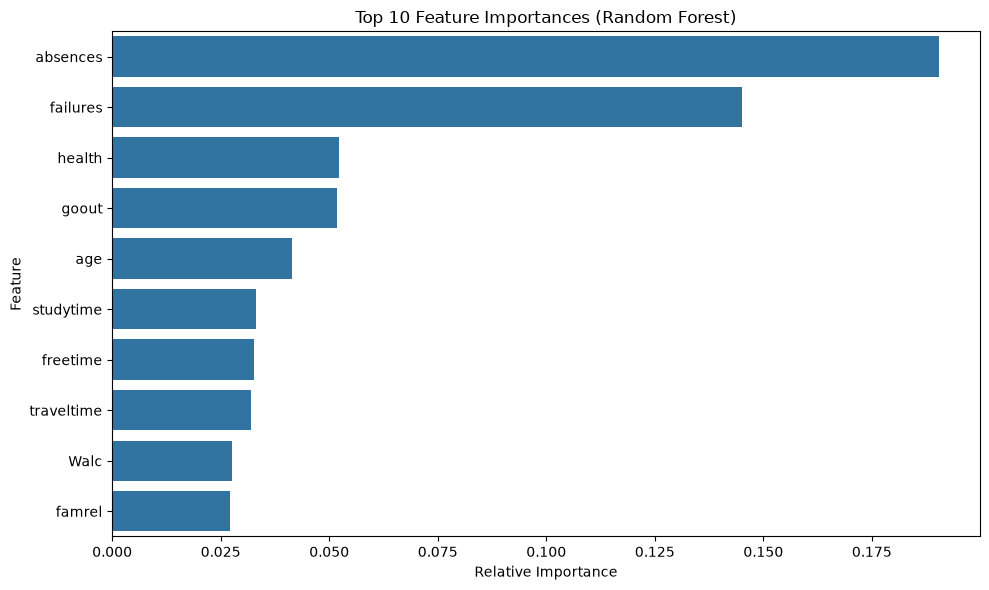

In [35]:
#Visualize 

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Limitations

This project have limitations. The dataset is relatively small and represents students from a limited geographic and educational context, which may restrict generalizability.
Additionally, the analysis is based on observational data. While the models identify associations between features and academic performance, they do not establish causal relationships. Important external factors not captured in the dataset may also influence outcomes.

Ethical Considerations

Predictive models applied to educational data must be interpreted with caution. There is a risk that such models could reinforce biases or be misused to label students unfairly.
The results of this project are intended for analytical and exploratory purposes only, emphasizing the importance of responsible and transparent use of machine learning in educational contexts.

Conclusion

This project demonstrated a complete machine learning workflow, including data preprocessing, model training, evaluation, and interpretation.
By comparing linear and non-linear models and analyzing feature importance, the study highlighted key factors associated with student performance while maintaining methodological rigor and avoiding data leakage.